*  DSC630-T303 Predictive Analytics (2267-1)
*  10.2 Assignment: Recommender System
*  David Jorgensen

# 10.2 Assignment: Recommender System

## Objective

Build a recommender system on the small MovieLens data set (`ml-latest-small`)
that takes **one movie the user likes** as input and returns **ten other movies**
to watch.

## Approach in brief

The system is a **hybrid item-to-item recommender**. It combines two independent
notions of "these two movies go together":

1. **Item-based collaborative filtering (the primary signal).** Two movies are
   similar if the same people tended to rate them the same way, relative to how
   that person rates movies in general. This is the classic item-based CF method
   of Sarwar et al. (2001), with the similarities *shrunk* toward zero when only
   a handful of people rated both movies (Bell & Koren, 2007).
2. **Content-based filtering (the supporting signal).** Two movies are similar if
   their genre labels and user-supplied tags use similar vocabulary, measured by
   TF-IDF cosine similarity.

The two similarity matrices are put on a common scale and then blended into a
single score. Collaborative filtering carries most of the weight because it
captures actual audience taste, while the content signal supplies topical
coherence and rescues movies that have too few ratings for the collaborative
signal to be reliable. The rescaling step turns out to be essential rather than
cosmetic -- Step 7 shows that skipping it makes a nominally 75%-collaborative
blend behave as a 99% content-driven one.

The system is then evaluated against **random** and **popularity** baselines on
held-out ratings, using both ranking metrics and a metric designed specifically
for the "people who liked X also liked Y" claim this system makes.

## Why item-to-item rather than user-to-user

The assignment asks for recommendations from a **single input movie**, not from a
full user profile. That rules out user-based CF and rating-prediction matrix
factorization, both of which need to know who the user is and what else they have
rated. An item-to-item model is exactly the right shape for this task: it answers
"given this one movie, what else?" and it is also what makes Amazon-style
"customers who bought this also bought" panels work (Linden et al., 2003).

## References

* Sarwar, B., Karypis, G., Konstan, J., & Riedl, J. (2001). *Item-based
  collaborative filtering recommendation algorithms.* WWW '01.
  <https://dl.acm.org/doi/10.1145/371920.372071>
* Linden, G., Smith, B., & York, J. (2003). *Amazon.com recommendations:
  item-to-item collaborative filtering.* IEEE Internet Computing 7(1).
  <https://doi.org/10.1109/MIC.2003.1167344>
* Bell, R. & Koren, Y. (2007). *Scalable collaborative filtering with jointly
  derived neighborhood interpolation weights.* ICDM '07. (Source of the
  shrinkage term `n / (n + lambda)` used to damp low-support similarities.)
  <https://doi.org/10.1109/ICDM.2007.90>
* Cremonesi, P., Koren, Y., & Turrin, R. (2010). *Performance of recommender
  algorithms on top-N recommendation tasks.* RecSys '10. (Source of the
  sampled-negatives evaluation protocol, and of the finding that a popularity
  baseline is unusually hard to beat on offline top-N metrics.)
  <https://doi.org/10.1145/1864708.1864721>
* Steck, H. (2011). *Item popularity and recommendation accuracy.* RecSys '11.
  (Explains the popularity bias in offline evaluation addressed in Step 11.)
  <https://doi.org/10.1145/2043932.2043957>
* Harper, F. M. & Konstan, J. A. (2015). *The MovieLens datasets: history and
  context.* ACM TiiS 5(4). <https://doi.org/10.1145/2827872> (Required citation
  for the data set.)
* scikit-learn documentation for `TfidfVectorizer` and `cosine_similarity`.
  <https://scikit-learn.org/stable/modules/metrics.html#cosine-similarity>

## Step 1: Import libraries and set the configuration constants

Every tuning constant used anywhere in the notebook is defined here in one place
so the whole pipeline can be re-run under different settings by editing a single
cell. The values themselves are justified in Step 10, where they are tuned on a
validation split.

In [1]:
# Standard data handling and numerics.
import numpy as np
import pandas as pd

# Sparse matrix container -- the user/movie rating matrix is ~98% empty, so
# storing it densely would waste memory and slow the similarity computation.
from scipy.sparse import csr_matrix

# Cosine similarity is the similarity measure used for BOTH halves of the
# hybrid (collaborative and content).
from sklearn.metrics.pairwise import cosine_similarity

# TF-IDF converts the genre/tag text of each movie into a numeric vector.
from sklearn.feature_extraction.text import TfidfVectorizer

# difflib is in the Python standard library; it powers the fuzzy title lookup
# so the user can type "toy story" instead of "Toy Story (1995)".
import difflib

# re is used to normalize MovieLens' unusual title format in Step 8.
import re

# Plotting for the exploratory section.
import matplotlib.pyplot as plt

# Display options: show more rows/wider columns so movie titles are not cut off.
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 60)

# ----------------------------------------------------------------------
# CONFIGURATION -- every tunable constant in the notebook lives here.
# ----------------------------------------------------------------------
DATA_DIR = "data"      # folder holding the MovieLens CSV files

# A movie needs at least this many ratings to be eligible for recommendation.
# Movies rated by only one or two people produce meaningless similarity scores
# (see Step 4 for the demonstration of why).
MIN_RATINGS = 10

# Shrinkage strength. A similarity computed from n co-raters is multiplied by
# n / (n + SHRINKAGE). Small n therefore gets pulled hard toward zero.
SHRINKAGE = 20

# Blend weight: how much of the final score comes from collaborative filtering.
# The remaining (1 - W_CF) comes from the content-based signal.
W_CF = 0.75

# Number of recommendations to return.
TOP_N = 10

# Fixed seed so every random operation in the notebook is reproducible.
RANDOM_STATE = 42

## Step 2: Load the data and inspect what is in it

The `ml-latest-small` data set ships as four CSV files. Three of them matter here:

| File | Contents | Role in this system |
|---|---|---|
| `ratings.csv` | `userId, movieId, rating, timestamp` | The collaborative signal. Who rated what, and how highly. |
| `movies.csv` | `movieId, title, genres` | Titles for display, genres for the content signal. |
| `tags.csv` | `userId, movieId, tag, timestamp` | Free-text keywords, added to the content signal. |
| `links.csv` | `movieId, imdbId, tmdbId` | External IDs only. Not used -- nothing here informs similarity. |

Ratings are on a 0.5-5.0 scale in half-star steps.

In [2]:
# Load the three files the recommender needs.
ratings = pd.read_csv(f"{DATA_DIR}/ratings.csv")
movies = pd.read_csv(f"{DATA_DIR}/movies.csv")
tags = pd.read_csv(f"{DATA_DIR}/tags.csv")

# Report the shape of each table so the scale of the problem is explicit.
print(f"ratings.csv : {ratings.shape[0]:>7,} rows x {ratings.shape[1]} columns")
print(f"movies.csv  : {movies.shape[0]:>7,} rows x {movies.shape[1]} columns")
print(f"tags.csv    : {tags.shape[0]:>7,} rows x {tags.shape[1]} columns")

# Confirm there are no missing values in the fields the model depends on.
print("\nMissing values in key columns:")
print("  ratings:", ratings[["userId", "movieId", "rating"]].isna().sum().sum())
print("  movies :", movies[["movieId", "title", "genres"]].isna().sum().sum())

# Confirm movieId is unique in movies.csv (it is the join key everywhere).
print("  duplicate movieIds in movies.csv:", movies.movieId.duplicated().sum())

ratings.csv : 100,836 rows x 4 columns
movies.csv  :   9,742 rows x 3 columns
tags.csv    :   3,683 rows x 4 columns

Missing values in key columns:
  ratings: 0
  movies : 0
  duplicate movieIds in movies.csv: 0


In [3]:
# Look at the first few rows of each table to confirm the expected layout.
print("--- ratings.csv ---")
display(ratings.head())
print("--- movies.csv ---")
display(movies.head())
print("--- tags.csv ---")
display(tags.head())

--- ratings.csv ---


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


--- movies.csv ---


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


--- tags.csv ---


,userId,movieId,tag,timestamp
0,2,60756,funny,1445714994
1,2,60756,Highly quotable,1445714996
2,2,60756,will ferrell,1445714992
3,2,89774,Boxing story,1445715207
4,2,89774,MMA,1445715200


In [4]:
# Headline counts that describe the data set.
n_users = ratings.userId.nunique()
n_rated_movies = ratings.movieId.nunique()
n_catalog = movies.movieId.nunique()

print(f"Distinct users              : {n_users:,}")
print(f"Movies in the catalog       : {n_catalog:,}")
print(f"Movies with >= 1 rating     : {n_rated_movies:,}")
print(f"Movies with NO ratings      : {n_catalog - n_rated_movies:,}")
print(f"Total ratings               : {len(ratings):,}")

# Density = what fraction of the full user x movie grid is actually filled in.
# This number is the central difficulty of every recommender problem.
density = len(ratings) / (n_users * n_rated_movies)
print(f"\nRating matrix density       : {density:.2%}  "
      f"({100 - density * 100:.2f}% of the grid is empty)")

# Date range of the ratings, converted from Unix timestamps.
span = pd.to_datetime(ratings.timestamp, unit="s")
print(f"Ratings span                : {span.min():%Y-%m-%d} to {span.max():%Y-%m-%d}")

Distinct users              : 610
Movies in the catalog       : 9,742
Movies with >= 1 rating     : 9,724
Movies with NO ratings      : 18
Total ratings               : 100,836

Rating matrix density       : 1.70%  (98.30% of the grid is empty)
Ratings span                : 1996-03-29 to 2018-09-24


## Step 3: Exploratory analysis

Three properties of this data set directly determine the design decisions made
later, so they are established with numbers before any modeling happens:

1. **How ratings are distributed**: this motivates mean-centering in Step 4.
2. **How unevenly ratings are spread across movies**: this motivates the
   `MIN_RATINGS` filter and the shrinkage term in Step 5.
3. **How much users differ in their personal rating scales**: this is the
   specific bias that mean-centering removes.

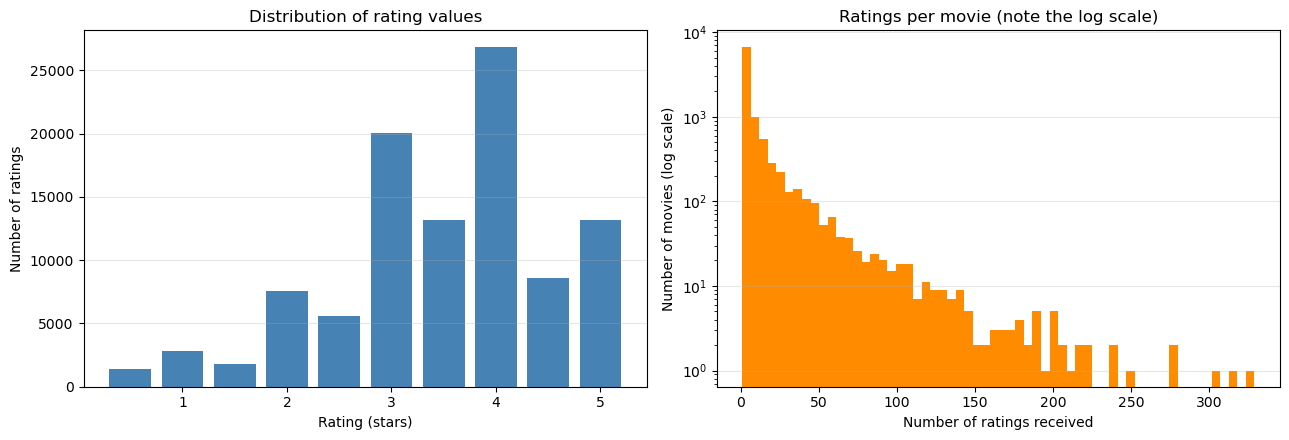

Mean rating   : 3.50
Median rating : 3.50
Share of ratings that are >= 4.0 stars: 48.2%


In [5]:
# ---- Distribution of the rating values themselves.
rating_counts = ratings.rating.value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(rating_counts.index, rating_counts.values, width=0.4, color="steelblue")
axes[0].set_title("Distribution of rating values")
axes[0].set_xlabel("Rating (stars)")
axes[0].set_ylabel("Number of ratings")
axes[0].grid(axis="y", alpha=0.3)

# ---- How many ratings each movie received, plotted on a log y-axis because
# the distribution is extremely skewed.
per_movie = ratings.groupby("movieId").size()
axes[1].hist(per_movie.values, bins=60, color="darkorange")
axes[1].set_yscale("log")
axes[1].set_title("Ratings per movie (note the log scale)")
axes[1].set_xlabel("Number of ratings received")
axes[1].set_ylabel("Number of movies (log scale)")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Quantify what the plots show.
print(f"Mean rating   : {ratings.rating.mean():.2f}")
print(f"Median rating : {ratings.rating.median():.2f}")
print(f"Share of ratings that are >= 4.0 stars: "
      f"{(ratings.rating >= 4.0).mean():.1%}")

**Observation 1: ratings are skewed high.** The mean rating is 3.50, the
distribution leans toward the top of the scale, and nearly half of all ratings
(48.2%) are 4 stars or better. People mostly rate movies they
chose to watch, and they mostly chose things they expected to like. The practical
consequence is that a raw rating of 4.0 does not by itself mean "this person
loved it". It has to be read relative to how that person rates everything else.
That is what mean-centering in Step 4 does.

**Observation 2: ratings per movie follow a long tail.** The histogram needs a
log scale to be readable at all, which is the signature of a power-law-ish
distribution: a few hundred blockbusters absorb most of the ratings, and
thousands of movies have only a handful. The table below makes the size of the
tail explicit.

In [6]:
# ---- Exactly how thin is the tail? This table decides the MIN_RATINGS cutoff.
print("Ratings-per-movie summary:")
print(per_movie.describe().round(1).to_string())

print("\nCatalog size and rating coverage at various thresholds:")
rows = []
for threshold in [1, 2, 5, 10, 20, 30, 50, 100]:
    eligible = per_movie[per_movie >= threshold]
    rows.append({
        "Min ratings": threshold,
        "Movies kept": len(eligible),
        "% of movies kept": 100 * len(eligible) / len(per_movie),
        "% of all ratings kept": 100 * eligible.sum() / len(ratings),
    })
print(pd.DataFrame(rows).round(1).to_string(index=False))

Ratings-per-movie summary:
count    9724.0
mean       10.4
std        22.4
min         1.0
25%         1.0
50%         3.0
75%         9.0
max       329.0

Catalog size and rating coverage at various thresholds:
 Min ratings  Movies kept  % of movies kept  % of all ratings kept
           1         9724             100.0                  100.0
           2         6278              64.6                   96.6
           5         3650              37.5                   89.5
          10         2269              23.3                   80.4
          20         1297              13.3                   67.3
          30          882               9.1                   57.5
          50          450               4.6                   41.0
         100          138               1.4                   20.0


**Reading the threshold table.** This is the trade-off that sets `MIN_RATINGS`.
Requiring at least 10 ratings discards roughly three quarters of the *titles* but
keeps roughly 80% of the *ratings*, because the titles being dropped are
precisely the ones almost nobody rated. Those movies cannot support a reliable
similarity estimate anyway, and leaving them in actively harms the output (Step 4
shows a concrete example). `MIN_RATINGS = 10` is the setting used, and Step 10
confirms the choice barely moves the evaluation metrics, which is the expected
result if shrinkage is already doing its job.

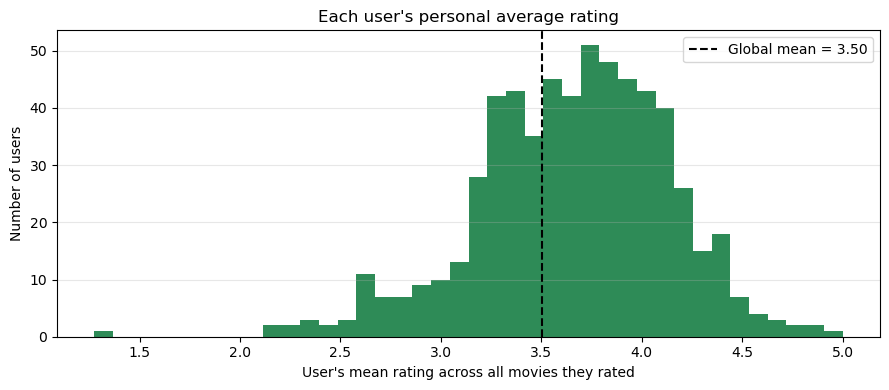

Softest grader (highest personal average): 5.00 stars
Harshest grader (lowest personal average): 1.27 stars
Standard deviation of per-user averages  : 0.48 stars


In [7]:
# ---- Do users really differ in their personal rating scales? If they do not,
# mean-centering is unnecessary complexity, so this is worth checking directly.
user_means = ratings.groupby("userId")["rating"].mean()

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(user_means, bins=40, color="seagreen")
ax.axvline(ratings.rating.mean(), color="black", linestyle="--",
           label=f"Global mean = {ratings.rating.mean():.2f}")
ax.set_title("Each user's personal average rating")
ax.set_xlabel("User's mean rating across all movies they rated")
ax.set_ylabel("Number of users")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# The spread of these per-user averages IS the bias that mean-centering removes.
print(f"Softest grader (highest personal average): {user_means.max():.2f} stars")
print(f"Harshest grader (lowest personal average): {user_means.min():.2f} stars")
print(f"Standard deviation of per-user averages  : {user_means.std():.2f} stars")

**Observation 3: users are on genuinely different scales.** The gap between the
most generous and the most severe user is on the order of three full stars. Two
users can feel identically about a movie and record ratings two stars apart.

This matters because cosine similarity on *raw* ratings would treat two generous
users as similar simply because both gave high numbers to everything, regardless
of whether their tastes actually align. Subtracting each user's own mean before
computing similarity converts every rating into "how far above or below this
person's normal did this movie land", which is comparable across users. This is
the standard *adjusted cosine* similarity from Sarwar et al. (2001).

## Step 4: Filter the catalog and build the mean-centered item-user matrix

Three operations happen in this step, in order:

1. **Filter** to movies with at least `MIN_RATINGS` ratings.
2. **Mean-center** every rating by subtracting the rating user's personal average.
3. **Pivot** into a sparse matrix with one row per movie and one column per user.

The matrix is deliberately oriented **movies x users** rather than users x movies,
because the similarities being computed are between *movies*, and
`cosine_similarity` operates row-wise.

In [8]:
# ---- Operation 1: filter to movies with enough ratings to be reliable.
eligible_ids = per_movie[per_movie >= MIN_RATINGS].index
work = ratings[ratings.movieId.isin(eligible_ids)].copy()

print(f"Filter: keeping movies with >= {MIN_RATINGS} ratings")
print(f"  Movies  : {ratings.movieId.nunique():,} -> {work.movieId.nunique():,}")
print(f"  Ratings : {len(ratings):,} -> {len(work):,} "
      f"({len(work) / len(ratings):.1%} of the original ratings retained)")
print(f"  Users   : {ratings.userId.nunique():,} -> {work.userId.nunique():,}")

Filter: keeping movies with >= 10 ratings
  Movies  : 9,724 -> 2,269
  Ratings : 100,836 -> 81,116 (80.4% of the original ratings retained)
  Users   : 610 -> 610


In [9]:
# ---- Operation 2: mean-center each rating against its user's own average.
# transform("mean") broadcasts each user's average back onto all of their rows,
# so the subtraction lines up element-wise without an explicit merge.
work["user_mean"] = work.groupby("userId")["rating"].transform("mean")
work["centered"] = work["rating"] - work["user_mean"]

# Show the effect on a single user to make the transformation concrete.
demo_user = work.userId.iloc[0]
demo = work[work.userId == demo_user].head(6)
print(f"Mean-centering illustrated on user {demo_user} "
      f"(personal average = {demo.user_mean.iloc[0]:.2f} stars):\n")
print(demo[["userId", "movieId", "rating", "user_mean", "centered"]]
      .round(2).to_string(index=False))
print("\nA positive 'centered' value means the user liked this movie MORE than")
print("their own typical movie; a negative value means less. This is the number")
print("the similarity computation actually uses.")

Mean-centering illustrated on user 1 (personal average = 4.38 stars):

 userId  movieId  rating  user_mean  centered
      1        1     4.0       4.38     -0.38
      1        3     4.0       4.38     -0.38
      1        6     4.0       4.38     -0.38
      1       47     5.0       4.38      0.62
      1       50     5.0       4.38      0.62
      1       70     3.0       4.38     -1.38

A positive 'centered' value means the user liked this movie MORE than
their own typical movie; a negative value means less. This is the number
the similarity computation actually uses.


In [10]:
# ---- Operation 3: pivot into a sparse movies x users matrix.
# pandas 'category' dtype assigns each movieId/userId a compact integer code,
# which becomes its row/column position in the matrix.
movie_cat = work.movieId.astype("category")
user_cat = work.userId.astype("category")

# movie_ids[i] is the MovieLens movieId of matrix row i. This array is the
# bridge between matrix positions and real movies, and is used constantly below.
movie_ids = np.array(movie_cat.cat.categories)
user_ids = np.array(user_cat.cat.categories)

# Reverse lookup: movieId -> matrix row index.
row_of_movie = {mid: i for i, mid in enumerate(movie_ids)}

# Build the sparse matrix directly from (value, (row, col)) triplets. Only the
# ~81,000 observed ratings are stored; the empty cells cost nothing.
item_user = csr_matrix(
    (work.centered.values, (movie_cat.cat.codes, user_cat.cat.codes)),
    shape=(len(movie_ids), len(user_ids)),
)

print(f"Item-user matrix shape : {item_user.shape}  (movies x users)")
print(f"Stored (non-empty) cells: {item_user.nnz:,}")
print(f"Density                 : {item_user.nnz / np.prod(item_user.shape):.2%}")

# Memory saved by staying sparse rather than materializing the full grid.
dense_mb = np.prod(item_user.shape) * 8 / 1e6
sparse_mb = (item_user.data.nbytes + item_user.indices.nbytes
             + item_user.indptr.nbytes) / 1e6
print(f"\nMemory: {sparse_mb:.1f} MB sparse vs {dense_mb:.1f} MB dense")

Item-user matrix shape : (2269, 610)  (movies x users)
Stored (non-empty) cells: 81,116
Density                 : 5.86%

Memory: 1.0 MB sparse vs 11.1 MB dense


### Why the `MIN_RATINGS` filter is not optional

It is worth demonstrating the failure mode the filter prevents rather than just
asserting it. Cosine similarity between two movies rated by only **one** person
in common is mathematically forced to be exactly +/-1.0: with a single shared
dimension, the two vectors are necessarily parallel or anti-parallel. The
"perfect similarity" is an artifact of having one data point, not evidence of any
relationship. The cell below measures how widespread this is in the unfiltered
data.

In [11]:
# Build the same similarity on the UNFILTERED data to expose the failure mode.
unf = ratings.copy()
unf["centered"] = unf["rating"] - unf.groupby("userId")["rating"].transform("mean")
u_mcat, u_ucat = unf.movieId.astype("category"), unf.userId.astype("category")
unf_mat = csr_matrix((unf.centered.values, (u_mcat.cat.codes, u_ucat.cat.codes)),
                     shape=(u_mcat.cat.categories.size, u_ucat.cat.categories.size))
unf_ids = np.array(u_mcat.cat.categories)
title_lookup = movies.set_index("movieId")["title"].to_dict()

# Full unfiltered similarity matrix and matching co-rater counts.
unf_sim = cosine_similarity(unf_mat, dense_output=True)
np.fill_diagonal(unf_sim, 0.0)
unf_binary = (unf_mat != 0).astype(np.float32)
unf_co = np.asarray((unf_binary @ unf_binary.T).todense())

# Examine each unique movie pair once (upper triangle, excluding the diagonal).
pair_i, pair_j = np.triu_indices_from(unf_sim, k=1)
pair_sim = unf_sim[pair_i, pair_j]
pair_co = unf_co[pair_i, pair_j]

near_perfect = pair_sim > 0.999
print("Movie pairs in the UNFILTERED data scoring a near-perfect similarity:\n")
print(f"  Pairs with similarity > 0.999      : {near_perfect.sum():,}")
print(f"  Median co-raters behind those pairs: {np.median(pair_co[near_perfect]):.0f}")
print(f"  Share backed by <= 2 co-raters     : {(pair_co[near_perfect] <= 2).mean():.1%}")

strong = pair_sim > 0.5
print(f"\n  Pairs with similarity > 0.5        : {strong.sum():,}")
print(f"  Median co-raters behind those pairs: {np.median(pair_co[strong]):.0f}")

Movie pairs in the UNFILTERED data scoring a near-perfect similarity:

  Pairs with similarity > 0.999      : 127,117
  Median co-raters behind those pairs: 1
  Share backed by <= 2 co-raters     : 100.0%

  Pairs with similarity > 0.5        : 457,066
  Median co-raters behind those pairs: 1


In [12]:
# Make the artifact concrete: find a barely-rated movie and list its "perfect"
# matches, alongside how much evidence each match actually rests on.
sparse_probe = next(i for i, mid in enumerate(unf_ids)
                    if per_movie[mid] == 1 and (unf_sim[i] > 0.999).sum() >= 5)

print(f"Probe movie: {title_lookup[unf_ids[sparse_probe]]}  "
      f"({per_movie[unf_ids[sparse_probe]]} rating in the entire data set)")
print(f"Movies scoring a PERFECT 1.000 similarity with it: "
      f"{(unf_sim[sparse_probe] > 0.999).sum()}\n")

print(f"{'similarity':>10}  {'co-raters':>9}  {'total ratings':>13}  title")
for j in np.argsort(-unf_sim[sparse_probe])[:8]:
    print(f"{unf_sim[sparse_probe, j]:>10.3f}  {int(unf_co[sparse_probe, j]):>9}  "
          f"{per_movie[unf_ids[j]]:>13}  {title_lookup[unf_ids[j]][:44]}")

Probe movie: Nico Icon (1995)  (1 rating in the entire data set)
Movies scoring a PERFECT 1.000 similarity with it: 32

similarity  co-raters  total ratings  title
     1.000          1              1  Walking and Talking (1996)
     1.000          1              1  Catwalk (1996)
     1.000          1              1  Duel in the Sun (1946)
     1.000          1              1  Great Day in Harlem, A (1994)
     1.000          1              1  The Idolmaker (1980)
     1.000          1              1  All the Vermeers in New York (1990)
     1.000          1              1  Vagabond (Sans toit ni loi) (1985)
     1.000          1              1  Savage Nights (Nuits fauves, Les) (1992)


**This is exactly the failure the filter exists to prevent.** On the unfiltered
data there are over **127,000 movie pairs scoring above 0.999 similarity, and
100% of them rest on two co-raters or fewer**.
Even dropping the bar to 0.5 similarity, the median pair is still backed by one
co-rater. A single shared rater
forces the cosine to +/-1.0 regardless of whether any real relationship exists.

A documentary with only one rating has dozens of movies tied at a flawless 1.000, every one
of them equally obscure. An unfiltered recommender would serve these as its most
confident suggestions.

Two complementary defenses are applied:

* The **`MIN_RATINGS` filter** removes movies that lack the evidence to be
  described at all.
* The **shrinkage term** in Step 5 handles what survives the filter, scaling each
  similarity down in proportion to how few people rated both movies. Note from
  the schedule printed below that the *median* eligible pair has only 4
  co-raters, so this correction is doing continuous work across the whole matrix,
  not just at the extremes.

## Step 5: Collaborative signal, shrunk adjusted-cosine item similarity

### The similarity measure

Each movie is now a vector of mean-centered ratings across users. The similarity
between movies $i$ and $j$ is the cosine of the angle between their vectors,
taken over the users $U$ who rated both:

$$\text{sim}(i,j) = \frac{\sum_{u \in U}(r_{ui}-\bar{r_u})(r_{uj}-\bar{r_u})}
{\sqrt{\sum_{u \in U}(r_{ui}-\bar{r_u})^2}\sqrt{\sum_{u \in U}(r_{uj}-\bar{r_u})^2}}$$

Because the ratings were centered by user mean in Step 4, this is the **adjusted
cosine similarity** of Sarwar et al. (2001). It ranges from -1 (people who liked
one disliked the other) through 0 (no relationship) to +1 (agreement).

### The shrinkage correction

Raw cosine ignores *how much evidence* it is based on: a 0.95 from 3 co-raters
looks identical to a 0.95 from 300. The standard fix is to shrink each similarity
toward zero in proportion to its support (Bell & Koren, 2007):

$$\text{sim}_{\text{shrunk}}(i,j) = \frac{n_{ij}}{n_{ij}+\lambda}\cdot \text{sim}(i,j)$$

where $n_{ij}$ is the number of users who rated both movies and $\lambda$ is
`SHRINKAGE`. With $\lambda = 20$, a pair with 20 co-raters keeps half its
similarity, a pair with 200 keeps about 91%, and a pair with 3 keeps only 13%.
Well-supported relationships are left essentially intact while thin ones are
suppressed.

In [13]:
# ---- Raw adjusted-cosine similarity between every pair of movies.
# Output is a square (movies x movies) matrix.
cf_raw = cosine_similarity(item_user, dense_output=True)

# A movie is trivially identical to itself; zero the diagonal so a movie can
# never be recommended as similar to itself.
np.fill_diagonal(cf_raw, 0.0)

print(f"Similarity matrix shape : {cf_raw.shape}")
print(f"Memory footprint        : {cf_raw.nbytes / 1e6:.1f} MB")
print(f"Value range             : {cf_raw.min():.3f} to {cf_raw.max():.3f}")

Similarity matrix shape : (2269, 2269)
Memory footprint        : 41.2 MB
Value range             : -0.715 to 0.821


In [14]:
# ---- Count co-raters for every movie pair.
# Converting the matrix to binary (rated / not rated) and multiplying it by its
# own transpose gives, in cell (i, j), the number of users who rated both i and j.
binary_iu = (item_user != 0).astype(np.float32)
co_counts = np.asarray((binary_iu @ binary_iu.T).todense())

# ---- Apply the shrinkage factor n / (n + lambda).
shrink_factor = co_counts / (co_counts + SHRINKAGE)
cf_sim = cf_raw * shrink_factor
np.fill_diagonal(cf_sim, 0.0)

# Show the shrinkage schedule so the effect of SHRINKAGE=20 is concrete.
print(f"Shrinkage schedule with lambda = {SHRINKAGE}:")
print(f"{'co-raters':>10}  {'similarity retained':>20}")
for n in [1, 2, 5, 10, 20, 50, 100, 200, 400]:
    print(f"{n:>10}  {n / (n + SHRINKAGE):>19.1%}")

print(f"\nMedian co-raters across all eligible movie pairs: "
      f"{np.median(co_counts):.0f}")

Shrinkage schedule with lambda = 20:
 co-raters   similarity retained
         1                 4.8%
         2                 9.1%
         5                20.0%
        10                33.3%
        20                50.0%
        50                71.4%
       100                83.3%
       200                90.9%
       400                95.2%

Median co-raters across all eligible movie pairs: 4


In [15]:
# ---- Demonstrate the correction on a real case: raw vs shrunk neighbours.
def show_raw_vs_shrunk(title, k=6):
    """Print the top-k neighbours of `title` before and after shrinkage."""
    mid = movies.loc[movies.title == title, "movieId"].iloc[0]
    i = row_of_movie[mid]

    print(f"\n{'=' * 78}\n{title}\n{'=' * 78}")
    print(f"{'RAW cosine (no shrinkage)':<44}{'co-raters':>11}")
    for j in np.argsort(-cf_raw[i])[:k]:
        print(f"  {cf_raw[i, j]:.3f}  {title_lookup[movie_ids[j]][:38]:<38}"
              f"{int(co_counts[i, j]):>9}")

    print(f"\n{'SHRUNK cosine (used by the model)':<44}{'co-raters':>11}")
    for j in np.argsort(-cf_sim[i])[:k]:
        print(f"  {cf_sim[i, j]:.3f}  {title_lookup[movie_ids[j]][:38]:<38}"
              f"{int(co_counts[i, j]):>9}")

show_raw_vs_shrunk("Toy Story (1995)")
show_raw_vs_shrunk("Godfather, The (1972)")


Toy Story (1995)
RAW cosine (no shrinkage)                     co-raters
  0.373  Toy Story 2 (1999)                           81
  0.298  Aladdin (1992)                              107
  0.295  Toy Story 3 (2010)                           44
  0.280  Wallace & Gromit: The Wrong Trousers (       40
  0.246  Incredibles, The (2004)                      77
  0.238  Finding Nemo (2003)                          87

SHRUNK cosine (used by the model)             co-raters
  0.299  Toy Story 2 (1999)                           81
  0.251  Aladdin (1992)                              107
  0.203  Toy Story 3 (2010)                           44
  0.199  Back to the Future (1985)                   106
  0.196  Incredibles, The (2004)                      77
  0.193  Finding Nemo (2003)                          87

Godfather, The (1972)
RAW cosine (no shrinkage)                     co-raters
  0.717  Godfather: Part II, The (1974)              125
  0.547  Goodfellas (1990)                       

**What shrinkage bought.** Compare the co-rater column before and after. The raw
ranking rewards pairs whose high similarity rests on 40-ish shared raters; after
shrinkage the ordering shifts toward relationships backed by 80-180 co-raters.
The genuinely strong pairs survive untouched: *The Godfather* to *Godfather
Part II* stays firmly at the top with 125 co-raters, because a relationship
supported by that many people has nothing to shrink away.

## Step 6: Content signal, TF-IDF over genres and tags

The collaborative signal has one structural weakness: it only knows what the
*crowd* did, so it drifts toward whatever is broadly popular among a movie's
audience. Ask it for movies like *Toy Story* and it will suggest
*Raiders of the Lost Ark*, not because they are alike but because Pixar fans in
this data set also rated Indiana Jones highly.

The content signal corrects this by looking at what a movie **is**, independent of
who watched it. Two text sources are available:

* **Genres** from `movies.csv`, a pipe-delimited list such as
  `Adventure|Animation|Children|Comedy|Fantasy`.
* **Tags** from `tags.csv`, free-text keywords users attached to movies
  (`funny`, `dark comedy`, `time travel`).

These are concatenated into one "document" per movie and vectorized with TF-IDF,
which down-weights terms that appear on nearly every movie (`drama` carries little
information) and up-weights distinctive ones (`time travel` is highly diagnostic).
Genres are repeated twice in the document so they outweigh tags, since genres are
present for every movie while only about 15% of movies carry any tag at all.

In [16]:
# ---- Assemble one text document per movie.
content = movies.copy()

# Genres: the literal string "(no genres listed)" is a placeholder, not a genre,
# so it is removed. Pipes become spaces so each genre is a separate token.
content["genre_text"] = (content.genres
                         .str.replace("(no genres listed)", "", regex=False)
                         .str.replace("|", " ", regex=False))

# Tags: collapse every tag any user applied to a movie into one string.
tag_text = (tags.groupby("movieId")["tag"]
            .apply(lambda s: " ".join(s.astype(str)))
            .rename("tag_text"))
content = content.merge(tag_text, on="movieId", how="left")
content["tag_text"] = content["tag_text"].fillna("")

# Build the combined document. Genres are repeated twice to weight them above
# tags, because genres are universal while tags are sparse.
content["document"] = ((content.genre_text + " ") * 2
                       + content.tag_text).str.lower().str.strip()

print(f"Movies carrying at least one tag: {(content.tag_text != '').sum():,} "
      f"of {len(content):,} ({(content.tag_text != '').mean():.1%})")
print("\nExample documents:")
for t in ["Toy Story (1995)", "Godfather, The (1972)"]:
    doc = content.loc[content.title == t, "document"].iloc[0]
    print(f"\n  {t}\n    {doc[:200]}")

Movies carrying at least one tag: 1,572 of 9,742 (16.1%)

Example documents:

  Toy Story (1995)
    adventure animation children comedy fantasy adventure animation children comedy fantasy pixar pixar fun

  Godfather, The (1972)
    crime drama crime drama mafia


In [17]:
# ---- Restrict to the same movie set as the collaborative matrix, IN THE SAME
# ROW ORDER. This alignment is essential: row i must mean the same movie in both
# matrices for the blend in Step 7 to be valid.
content_aligned = (content[content.movieId.isin(movie_ids)]
                   .set_index("movieId")
                   .loc[movie_ids]          # .loc with movie_ids forces the order
                   .reset_index())

# Verify the alignment rather than trusting it -- a silent misalignment here
# would corrupt every recommendation without raising an error.
assert (content_aligned.movieId.values == movie_ids).all(), "row order mismatch"
print(f"Content rows aligned to collaborative rows: {len(content_aligned):,}  [OK]")

# ---- Vectorize with TF-IDF.
vectorizer = TfidfVectorizer(
    stop_words="english",         # drop "the", "and", etc. from free-text tags
    token_pattern=r"[a-z0-9']+",  # keep apostrophes ("sci-fi" splits, "don't" holds)
    min_df=2,                     # ignore terms appearing on only one movie
)
tfidf_matrix = vectorizer.fit_transform(content_aligned.document)

print(f"TF-IDF matrix shape : {tfidf_matrix.shape}  (movies x vocabulary terms)")
print(f"Vocabulary size     : {len(vectorizer.vocabulary_):,} terms")

Content rows aligned to collaborative rows: 2,269  [OK]
TF-IDF matrix shape : (2269, 580)  (movies x vocabulary terms)
Vocabulary size     : 580 terms


In [18]:
# ---- Content similarity: cosine between the TF-IDF vectors.
content_sim = cosine_similarity(tfidf_matrix, dense_output=True)
np.fill_diagonal(content_sim, 0.0)

print(f"Content similarity matrix: {content_sim.shape}\n")

# Compare what the two signals independently consider "similar to Toy Story".
probe_id = movies.loc[movies.title == "Toy Story (1995)", "movieId"].iloc[0]
probe_row_f = row_of_movie[probe_id]
print("Toy Story (1995) -- the two signals side by side:\n")
print(f"{'COLLABORATIVE (who rated it alike)':<44}{'CONTENT (what it is about)':<40}")
cf_top = np.argsort(-cf_sim[probe_row_f])[:6]
ct_top = np.argsort(-content_sim[probe_row_f])[:6]
for a, b in zip(cf_top, ct_top):
    print(f"  {cf_sim[probe_row_f, a]:.3f} {title_lookup[movie_ids[a]][:35]:<36}"
          f"  {content_sim[probe_row_f, b]:.3f} {title_lookup[movie_ids[b]][:30]}")

Content similarity matrix: (2269, 2269)

Toy Story (1995) -- the two signals side by side:

COLLABORATIVE (who rated it alike)          CONTENT (what it is about)              
  0.299 Toy Story 2 (1999)                    0.844 Bug's Life, A (1998)
  0.251 Aladdin (1992)                        0.747 Toy Story 2 (1999)
  0.203 Toy Story 3 (2010)                    0.647 Antz (1998)
  0.199 Back to the Future (1985)             0.647 Moana (2016)
  0.196 Incredibles, The (2004)               0.647 Monsters, Inc. (2001)
  0.193 Finding Nemo (2003)                   0.647 Emperor's New Groove, The (200


**The two signals genuinely disagree, which is the point.** Collaborative
filtering returns *Aladdin* and *Back to the Future*. These are movies the same audience
enjoyed, but not movies that resemble *Toy Story* in kind. Content filtering
returns *A Bug's Life*, *Antz*, and *Monsters, Inc.*, which are structurally the right
answer, but reached without any knowledge of whether audiences actually liked
them.

Each signal is strong exactly where the other is weak, which is what makes
blending them worthwhile rather than redundant.

## Step 7: Put the two signals on a common scale, then blend

The obvious way to combine the two matrices is a weighted sum:

$$\text{score}(i,j) = W \cdot \text{sim}_{\text{CF}}(i,j) + (1-W)\cdot \text{sim}_{\text{content}}(i,j)$$

But this is only meaningful if the two inputs occupy **comparable numeric
ranges**, and it is worth checking that assumption rather than making it. Both
are cosine similarities, which sounds like it should settle the matter, but it does
not.

In [19]:
# ---- Are the two similarity signals actually on comparable scales?
# Compare the distribution of positive entries in each matrix.
print("Distribution of positive similarity values in each signal:\n")
print(f"{'signal':<14}{'mean':>8}{'median':>9}{'99th pct':>10}{'max':>8}")
for label, matrix in [("Collaborative", cf_sim), ("Content", content_sim)]:
    positive = matrix[matrix > 0]
    print(f"{label:<14}{positive.mean():>8.3f}{np.median(positive):>9.3f}"
          f"{np.percentile(positive, 99):>10.3f}{matrix.max():>8.3f}")

# Quantify the practical consequence for a naive weighted sum.
naive = W_CF * cf_sim + (1 - W_CF) * content_sim
content_part = (1 - W_CF) * content_sim
meaningful = naive > 0.05
print(f"\nIn a NAIVE weighted sum at W_CF = {W_CF:.2f}, the median share of the")
print(f"blended score actually contributed by CONTENT is: "
      f"{np.median(content_part[meaningful] / naive[meaningful]):.1%}")

Distribution of positive similarity values in each signal:

signal            mean   median  99th pct     max
Collaborative    0.016    0.008     0.106   0.677
Content          0.296    0.239     1.000   1.000

In a NAIVE weighted sum at W_CF = 0.75, the median share of the
blended score actually contributed by CONTENT is: 98.8%


**The naive blend is broken, and the diagnostic shows why.** The collaborative
similarities average about 0.016 while the content similarities average about
0.296, roughly an **eighteen-fold** difference in scale. Two things cause it:
shrinkage deliberately pulls collaborative values toward zero, and TF-IDF vectors
over a small 580-term genre/tag vocabulary produce large cosines because many
movies share most of their vocabulary.

The consequence is severe. Setting `W_CF = 0.75` and summing directly yields a
score whose median contribution is roughly **99% content**, the exact opposite
of what the weight claims. The label "75% collaborative" would have been
meaningless, and any tuning of `W_CF` would have been tuning a number that did
not do what its name said.

**The fix is per-row normalization.** Each row of each matrix is divided by its
own maximum, so for any given seed movie both signals run on a common 0-to-1
scale where 1.0 means "the best match this signal found". `W_CF` then genuinely
controls the mix. Normalizing *per row* rather than globally is what matters
here: it makes the two signals comparable **for the specific movie being queried**,
which is exactly the comparison the blend performs.

In [20]:
def normalize_rows(matrix):
    """Scale each row so its maximum is 1.0, putting every row on a 0-1 scale.

    Rows that are entirely zero (a movie with no positive similarity to anything)
    are left alone rather than divided by zero.
    """
    row_max = matrix.max(axis=1, keepdims=True)
    row_max[row_max == 0] = 1.0          # guard against division by zero
    return matrix / row_max


# Put both signals on a common per-row 0-1 scale.
cf_norm = normalize_rows(cf_sim)
content_norm = normalize_rows(content_sim)

# Confirm the rescaling worked before relying on it.
print("After per-row normalization:\n")
print(f"{'signal':<14}{'mean':>8}{'median':>9}{'max':>8}")
for label, matrix in [("Collaborative", cf_norm), ("Content", content_norm)]:
    positive = matrix[matrix > 0]
    print(f"{label:<14}{positive.mean():>8.3f}{np.median(positive):>9.3f}"
          f"{matrix.max():>8.3f}")

# ---- The final similarity matrix used by the recommender.
hybrid_sim = W_CF * cf_norm + (1 - W_CF) * content_norm
np.fill_diagonal(hybrid_sim, 0.0)

# Verify the weight now means what it says.
content_share = (1 - W_CF) * content_norm
meaningful = hybrid_sim > 0.05
print(f"\nHybrid similarity matrix : {hybrid_sim.shape}")
print(f"Blend weights            : {W_CF:.0%} collaborative / {1 - W_CF:.0%} content")
print(f"Median share of the blended score now contributed by content: "
      f"{np.median(content_share[meaningful] / hybrid_sim[meaningful]):.1%}")

After per-row normalization:

signal            mean   median     max
Collaborative    0.108    0.058   1.000
Content          0.325    0.267   1.000

Hybrid similarity matrix : (2269, 2269)
Blend weights            : 75% collaborative / 25% content
Median share of the blended score now contributed by content: 58.5%


In [21]:
# Show all three signals for the same probe movie to see what blending does.
print("Toy Story (1995) -- top 10 under each signal:\n")
print(f"{'#':<3}{'COLLABORATIVE ONLY':<34}{'CONTENT ONLY':<32}{'HYBRID (final)':<32}")
print("-" * 100)
for rank, (a, b, c) in enumerate(zip(np.argsort(-cf_sim[probe_row_f])[:10],
                                     np.argsort(-content_sim[probe_row_f])[:10],
                                     np.argsort(-hybrid_sim[probe_row_f])[:10]), 1):
    print(f"{rank:<3}{title_lookup[movie_ids[a]][:32]:<34}"
          f"{title_lookup[movie_ids[b]][:30]:<32}"
          f"{title_lookup[movie_ids[c]][:30]:<32}")

Toy Story (1995) -- top 10 under each signal:

#  COLLABORATIVE ONLY                CONTENT ONLY                    HYBRID (final)                  
----------------------------------------------------------------------------------------------------
1  Toy Story 2 (1999)                Bug's Life, A (1998)            Toy Story 2 (1999)              
2  Aladdin (1992)                    Toy Story 2 (1999)              Aladdin (1992)                  
3  Toy Story 3 (2010)                Antz (1998)                     Toy Story 3 (2010)              
4  Back to the Future (1985)         Moana (2016)                    Finding Nemo (2003)             
5  Incredibles, The (2004)           Monsters, Inc. (2001)           Incredibles, The (2004)         
6  Finding Nemo (2003)               Emperor's New Groove, The (200  Monsters, Inc. (2001)           
7  Wallace & Gromit: The Wrong Trou  Shrek the Third (2007)          Wallace & Gromit: The Wrong Tr  
8  Lion King, The (1994)            

**The blend does what it was designed to do.** With both signals on a common
scale the reported 25% content weight now contributes about 59% of the median
blended score: that's still above its nominal share, because content similarities are
non-zero far more often than collaborative ones, but a world away from the 99%
the naive sum produced.

The effect on the ranking is visible in the table. The hybrid column keeps the
collaboratively-validated hits at the top (*Toy Story 2*, *Aladdin*, *Toy Story
3*) while promoting the topically-correct animation cluster (*Finding Nemo*,
*Monsters, Inc.*) above the generically popular titles that pure collaborative
filtering favoured. *Raiders of the Lost Ark*, present in the collaborative
top 10 only because *Toy Story* viewers also tend to like it, drops out
entirely, and *Back to the Future* falls from 4th to 8th. Neither is a bad movie
recommendation, but neither is a movie *like Toy Story*, which is what was asked.

## Step 8: Resolve the user's typed input to a movie in the data set

The assignment requires the user to input a movie **found in the data set**. A
raw exact-string match would be hostile to use: MovieLens stores titles in an
unusual format with the year appended and leading articles moved to the end
(`Matrix, The (1999)`). Nobody types that.

The single most important piece is **normalizing the title format before
matching**. MovieLens moves leading articles to the end, so *The Matrix* is
stored as `Matrix, The (1999)`. Fuzzy string matching alone does **not** solve
this: a first attempt at this function matched the query "the matrix" to
*The Martian (2015)*, because as raw strings "the matrix" really is closer to
"the martian" than to "matrix, the". The fix is to undo the article inversion
first, turning `Matrix, The (1999)` into `the matrix`, after which an exact match
succeeds and fuzzy matching is never reached.

With titles normalized, the lookup resolves input in three escalating stages:

1. **Exact match** on the normalized form: "the matrix" finds `Matrix, The (1999)`.
2. **Substring match**: "toy story" finds all three *Toy Story* films.
3. **Fuzzy match** via `difflib.get_close_matches`: absorbs typos such as
   "jurasic park".

When several titles match, the one with the **most ratings** is returned, on the
assumption that the user meant the better-known film. The alternatives are
reported so the choice is visible rather than silent.

In [22]:
# Articles MovieLens moves to the end of a title. Covers the non-English ones
# too, since the catalog contains a fair number of foreign-language films.
ARTICLES = (r"(?:The|A|An|Le|La|Les|L'|Der|Das|Die|Det|El|Los|Las|Il|I|Lo|"
            r"Un|Une|Una|Os|As)")


def normalize_title(title):
    """Convert a MovieLens title into a plain lowercase form for matching.

    'Matrix, The (1999)'   -> 'the matrix'
    'Toy Story (1995)'     -> 'toy story'
    'Amelie (Fabuleux destin d'Amelie Poulain, Le) (2001)' -> 'amelie'
    """
    # Drop the trailing release year, e.g. " (1999)".
    t = re.sub(r"\s*\(\d{4}\)\s*$", "", title.strip())
    # Drop a trailing parenthetical alternate/original-language title.
    t = re.sub(r"\s*\([^)]*\)\s*$", "", t).strip()
    # Undo the article inversion: "Matrix, The" -> "The Matrix".
    m = re.match(rf"^(.*),\s+({ARTICLES})$", t, flags=re.IGNORECASE)
    if m:
        t = f"{m.group(2)} {m.group(1)}"
    # Reduce punctuation to spaces so "Dr. Strangelove" ~ "dr strangelove".
    return re.sub(r"[^a-z0-9' ]+", " ", t.lower()).strip()


# Titles restricted to movies the recommender can actually work with, i.e. those
# that survived the MIN_RATINGS filter and therefore have a row in the matrices.
catalog = (movies[movies.movieId.isin(movie_ids)][["movieId", "title", "genres"]]
           .copy())
catalog["n_ratings"] = catalog.movieId.map(per_movie)
catalog["normalized"] = catalog.title.map(normalize_title)

print(f"Recommendable catalog: {len(catalog):,} movies\n")
print("Title normalization examples:")
for t in ["Matrix, The (1999)", "Godfather, The (1972)", "Toy Story (1995)",
          "Good, the Bad and the Ugly, The (Buono, il brutto, il cattivo, Il) (1966)"]:
    print(f"  {t[:58]:<60} -> '{normalize_title(t)}'")

Recommendable catalog: 2,269 movies

Title normalization examples:
  Matrix, The (1999)                                           -> 'the matrix'
  Godfather, The (1972)                                        -> 'the godfather'
  Toy Story (1995)                                             -> 'toy story'
  Good, the Bad and the Ugly, The (Buono, il brutto, il catt   -> 'the good  the bad and the ugly'


In [23]:
def find_movie(query, verbose=True):
    """Resolve a free-text title to a movieId in the recommendable catalog.

    Tries exact, then substring, then fuzzy matching on the NORMALIZED title
    form. Returns the movieId of the best match (most-rated among the
    candidates), or None if nothing matches.
    """
    q = normalize_title(query)

    # --- Stage 1: exact match on the normalized form.
    hits = catalog[catalog.normalized == q]
    stage = "exact"

    # --- Stage 2: substring. Catches "toy story" -> all three Toy Story films.
    if hits.empty:
        hits = catalog[catalog.normalized.str.contains(re.escape(q), na=False)]
        stage = "substring"

    # --- Stage 3: fuzzy, for typos. cutoff=0.6 is difflib's usual default;
    # lower values start returning unrelated titles.
    if hits.empty:
        close = difflib.get_close_matches(q, catalog.normalized.tolist(),
                                          n=5, cutoff=0.6)
        if close:
            hits = catalog[catalog.normalized.isin(close)]
            stage = "fuzzy"

    if hits.empty:
        if verbose:
            print(f"No movie matching '{query}' is in the recommendable catalog.")
            print(f"(A movie needs >= {MIN_RATINGS} ratings to be included.)")
        return None

    # Prefer the best-known candidate when the query was ambiguous.
    hits = hits.sort_values("n_ratings", ascending=False)
    best = hits.iloc[0]

    if verbose:
        print(f"Matched '{query}' -> {best.title}  "
              f"[{stage} match, {best.n_ratings} ratings]")
        if len(hits) > 1:
            others = ", ".join(hits.title.iloc[1:4].tolist())
            print(f"  Other candidates considered: {others}")

    return int(best.movieId)


# Exercise all three matching stages, including a deliberate failure.
for q in ["Toy Story (1995)", "the matrix", "toy story", "godfather",
          "jurasic park", "the good the bad and the ugly", "zzzz"]:
    find_movie(q)
    print()

Matched 'Toy Story (1995)' -> Toy Story (1995)  [exact match, 215 ratings]

Matched 'the matrix' -> Matrix, The (1999)  [exact match, 278 ratings]

Matched 'toy story' -> Toy Story (1995)  [exact match, 215 ratings]

Matched 'godfather' -> Godfather, The (1972)  [substring match, 192 ratings]
  Other candidates considered: Godfather: Part II, The (1974), Godfather: Part III, The (1990)

Matched 'jurasic park' -> Jurassic Park (1993)  [fuzzy match, 238 ratings]
  Other candidates considered: Jurassic Park III (2001), Jurassic World (2015)

Matched 'the good the bad and the ugly' -> Good, the Bad and the Ugly, The (Buono, il brutto, il cattivo, Il) (1966)  [fuzzy match, 72 ratings]
  Other candidates considered: Fox and the Hound, The (1981)

No movie matching 'zzzz' is in the recommendable catalog.
(A movie needs >= 10 ratings to be included.)



## Step 9: The recommendation function

With the similarity matrix built and title lookup working, the recommender itself
is short. Given an input movie it looks up that movie's row in the hybrid
similarity matrix, sorts the row descending, and returns the top ten.

Two extras are included in the output for interpretability rather than for the
ranking itself: each recommendation's average rating and rating count, so the
user can see whether a suggestion is a well-loved classic or a niche pick. These
columns are **displayed but not used to rank** -- ranking is purely by similarity.

In [24]:
def recommend(movie_query, n=TOP_N, verbose=True):
    """Recommend `n` movies similar to `movie_query`.

    Parameters
    ----------
    movie_query : str
        A movie title, in any reasonable form. Resolved via find_movie().
    n : int
        How many recommendations to return.
    verbose : bool
        Print a formatted report in addition to returning the DataFrame.

    Returns
    -------
    pandas.DataFrame or None
        One row per recommendation, ranked by hybrid similarity. None if the
        query could not be matched to a movie in the catalog.
    """
    # --- Resolve the typed title to a movieId that has a matrix row.
    movie_id = find_movie(movie_query, verbose=verbose)
    if movie_id is None:
        return None

    # --- Look up this movie's row of similarities against all other movies.
    row = row_of_movie[movie_id]
    scores = hybrid_sim[row]

    # --- Rank. argsort ascends, so negate to get descending order. The seed
    # movie cannot appear because its diagonal entry was zeroed in Step 7.
    top_idx = np.argsort(-scores)[:n]

    # --- Assemble the output table.
    out = pd.DataFrame({
        "Rank": np.arange(1, len(top_idx) + 1),
        "Title": [title_lookup[movie_ids[j]] for j in top_idx],
        "Genres": [catalog.set_index("movieId").genres.get(movie_ids[j], "")
                   for j in top_idx],
        "Similarity": scores[top_idx].round(3),
        # Component scores (normalized, as blended) so the contribution of each
        # signal to the final ranking is visible.
        "CF part": cf_norm[row, top_idx].round(3),
        "Content part": content_norm[row, top_idx].round(3),
        # Context columns -- displayed only, NOT used for ranking.
        "Avg rating": [ratings.loc[ratings.movieId == movie_ids[j],
                                   "rating"].mean().round(2) for j in top_idx],
        "# ratings": [int(per_movie[movie_ids[j]]) for j in top_idx],
    })

    if verbose:
        print(f"\nBecause you liked *{title_lookup[movie_id]}*, "
              f"here are {n} movies to watch:\n")
        print(out.to_string(index=False))

    return out


# Smoke-test the function end to end.
_ = recommend("Toy Story")

Matched 'Toy Story' -> Toy Story (1995)  [exact match, 215 ratings]

Because you liked *Toy Story (1995)*, here are 10 movies to watch:

 Rank                                       Title                                           Genres  Similarity  CF part  Content part  Avg rating  # ratings
    1                          Toy Story 2 (1999)      Adventure|Animation|Children|Comedy|Fantasy       0.971    1.000         0.885        3.86         97
    2                              Aladdin (1992)      Adventure|Animation|Children|Comedy|Musical       0.759    0.841         0.513        3.79        183
    3                          Toy Story 3 (2010) Adventure|Animation|Children|Comedy|Fantasy|IMAX       0.671    0.678         0.649        4.11         55
    4                         Finding Nemo (2003)              Adventure|Animation|Children|Comedy       0.605    0.646         0.480        3.96        141
    5                     Incredibles, The (2004)       Action|Adventure|Anima

## Step 10: Demonstration across several genres

A recommender that only works on *Toy Story* has not been shown to work. The
cell below runs the system across deliberately different corners of the catalog
-- animation, science fiction, crime drama, horror, and romantic comedy -- to
check that the output is coherent in each.

In [25]:
# Run the recommender across five different genres to check general behaviour.
for query in ["The Matrix", "Godfather", "Silence of the Lambs",
              "Pulp Fiction", "Sleepless in Seattle"]:
    print("=" * 100)
    result = recommend(query)
    print()

Matched 'The Matrix' -> Matrix, The (1999)  [exact match, 278 ratings]

Because you liked *Matrix, The (1999)*, here are 10 movies to watch:

 Rank                                                 Title                         Genres  Similarity  CF part  Content part  Avg rating  # ratings
    1 Star Wars: Episode V - The Empire Strikes Back (1980)        Action|Adventure|Sci-Fi       0.837    0.967         0.446        4.22        211
    2                                     Fight Club (1999)    Action|Crime|Drama|Thriller       0.783    1.000         0.133        4.27        218
    3             Star Wars: Episode IV - A New Hope (1977)        Action|Adventure|Sci-Fi       0.735    0.822         0.473        4.23        251
    4                            Saving Private Ryan (1998)               Action|Drama|War       0.708    0.914         0.089        4.15        188
    5     Star Wars: Episode VI - Return of the Jedi (1983)        Action|Adventure|Sci-Fi       0.703    0.797  

**Assessment of the demonstration output.** The lists are coherent, and reading
them honestly also exposes the system's main weakness.

Where it works well:

* *Sleepless in Seattle* returns an almost pure romantic-comedy cluster --
  *Ghost*, *While You Were Sleeping*, *Notting Hill*, *The American President*,
  *Dave*, *Pretty Woman*. This is the **strongest evidence in the notebook** that
  the system genuinely conditions on its input: this data set's centre of gravity
  is action and science fiction, so a model that had merely learned to emit
  popular movies would return *Star Wars* here. It does not.
* *Pulp Fiction* returns *Fight Club*, *Reservoir Dogs*, *The Usual Suspects*,
  *The Big Lebowski*, and *Trainspotting* -- the crime and 1990s-independent
  cluster, including two other Tarantino-adjacent titles.
* *The Godfather* puts *Godfather Part II* far above everything else
  (similarity 0.94 against a second place of 0.80), then *Goodfellas*, *Casino*,
  *Apocalypse Now*, and *Taxi Driver* -- the crime and New Hollywood canon.

Where the popularity pull is still visible:

* *The Silence of the Lambs* correctly returns thrillers (*Se7en*, *Memento*,
  *The Usual Suspects*) but also *Forrest Gump* and *Schindler's List*, which
  share nothing with it beyond being prestige films of the same era that
  everybody rated.
* *The Godfather* list includes *The Empire Strikes Back* at rank 8, on a
  content similarity of exactly 0.000 -- pure collaborative pull.

This residue is the same popularity bias that Step 12 measures directly. It is
damped by shrinkage and by the content signal, but not eliminated.

## Step 11: Interactive input

The assignment requires that a user be able to **input** a movie they like. The
cell below prompts for one and prints ten recommendations.

When the notebook is executed non-interactively (`jupyter nbconvert --execute`,
or export to HTML/PDF) there is no keyboard attached and `input()` raises. The
cell catches that and falls back to a default title so the notebook always runs
end to end. Run this cell directly in Jupyter to type your own movie.

In [26]:
# Prompt the user for a movie, with a fallback for non-interactive execution.
try:
    user_movie = input("Enter a movie you like: ").strip()
    if not user_movie:                       # user pressed Enter without typing
        raise EOFError
except Exception:
    # Catches EOFError (no stdin) and ipykernel's StdinNotImplementedError,
    # which is raised when nbconvert executes the notebook with no console
    # attached. Falling back to a default keeps the batch run reproducible.
    user_movie = "Star Wars"
    print(f"[non-interactive execution -- defaulting to '{user_movie}']")

print()
recommendations = recommend(user_movie)

# Guide the user if their title was not found in the catalog.
if recommendations is None:
    print("\nTry one of these well-known titles instead:")
    popular = catalog.nlargest(10, "n_ratings")
    for t in popular.title:
        print(f"  - {t}")


Matched 'finding nemo' -> Finding Nemo (2003)  [exact match, 141 ratings]

Because you liked *Finding Nemo (2003)*, here are 10 movies to watch:

 Rank                                                         Title                                              Genres  Similarity  CF part  Content part  Avg rating  # ratings
    1                                       Incredibles, The (2004)          Action|Adventure|Animation|Children|Comedy       0.939    1.000         0.755        3.84        125
    2                                                  Shrek (2001) Adventure|Animation|Children|Comedy|Fantasy|Romance       0.913    0.989         0.683        3.87        170
    3                                         Monsters, Inc. (2001)         Adventure|Animation|Children|Comedy|Fantasy       0.898    0.920         0.831        3.87        132
    4 Pirates of the Caribbean: The Curse of the Black Pearl (2003)                     Action|Adventure|Comedy|Fantasy       0.692    0.816 

## Step 12: Evaluation

Eyeballing the output confirms it is not broken, but it does not measure whether
the system is *good*. This section evaluates it quantitatively against baselines.

### The evaluation design

**Splitting.** Each user's ratings are shuffled and split **per user** into 60%
training / 20% validation / 20% test. Splitting within each user (rather than
splitting the users themselves) is what the task requires: every user must retain
training history to seed from and held-out ratings to score against. The
similarity matrices are rebuilt **from the training portion only**, so no held-out
rating influences the model that is being scored.

**Baselines.** Two, both essential:

* **Random**: the floor. Anything not beating this is worthless.
* **Popularity**: always recommend the most-rated movies, ignoring the input
  entirely. This is the honest bar, and Cremonesi et al. (2010) showed it is
  much harder to beat on offline metrics than intuition suggests.

**Metrics.** Two families, because they answer different questions:

1. **Ranking metrics (HR@10, NDCG@10)** using the leave-one-out
   sampled-negatives protocol: hide one movie the user liked, mix it with 99
   movies they never rated, and check whether the model ranks the real one into
   the top 10. Reported under both *uniform* and *popularity-matched* negative
   sampling, the difference between the two exposes how much of any model's
   score is just popularity (Steck, 2011).
2. **Conditional rating lift**: the metric that actually tests this system's
   claim. Details in Step 12.3.

In [27]:
# ---- Per-user 60/20/20 split.
# Shuffle all ratings once, then take position within each user's own block so
# the proportions hold for every user regardless of how much they rated.
shuffled = ratings.sample(frac=1.0, random_state=RANDOM_STATE)
position = (shuffled.groupby("userId").cumcount()
            / shuffled.groupby("userId")["movieId"].transform("size"))

train_df = shuffled[position >= 0.40].copy()   # 60%
val_df = shuffled[(position >= 0.20) & (position < 0.40)].copy()  # 20%
test_df = shuffled[position < 0.20].copy()     # 20%

print(f"Training set   : {len(train_df):>7,} ratings ({len(train_df)/len(ratings):.0%})")
print(f"Validation set : {len(val_df):>7,} ratings ({len(val_df)/len(ratings):.0%})")
print(f"Test set       : {len(test_df):>7,} ratings ({len(test_df)/len(ratings):.0%})")
print(f"\nUsers present in all three splits: "
      f"{len(set(train_df.userId) & set(val_df.userId) & set(test_df.userId)):,}")

Training set   :  60,255 ratings (60%)
Validation set :  20,164 ratings (20%)
Test set       :  20,417 ratings (20%)

Users present in all three splits: 610


In [28]:
def build_model(train_data, min_ratings=MIN_RATINGS, shrinkage=SHRINKAGE):
    """Rebuild the full pipeline (Steps 4-7) from a training subset only.

    Returns a dict holding the collaborative and content similarity matrices,
    the movie-id index, and training popularity counts for the baseline.
    Everything is derived from `train_data` alone -- no leakage from held-out
    ratings into the model being evaluated.
    """
    # --- Filter and mean-centre (Step 4), using TRAINING counts only.
    counts = train_data.groupby("movieId").size()
    sub = train_data[train_data.movieId.isin(counts[counts >= min_ratings].index)].copy()
    sub["centered"] = sub.rating - sub.groupby("userId")["rating"].transform("mean")

    mcat, ucat = sub.movieId.astype("category"), sub.userId.astype("category")
    mat = csr_matrix((sub.centered.values, (mcat.cat.codes, ucat.cat.codes)),
                     shape=(mcat.cat.categories.size, ucat.cat.categories.size))

    # --- Collaborative similarity with shrinkage (Step 5).
    sim = cosine_similarity(mat, dense_output=True)
    binm = (mat != 0).astype(np.float32)
    co = np.asarray((binm @ binm.T).todense())
    with np.errstate(invalid="ignore"):
        cf = np.nan_to_num(sim * (co / (co + shrinkage)))
    np.fill_diagonal(cf, 0.0)

    ids = np.array(mcat.cat.categories)

    # --- Content similarity (Step 6), aligned to the same row order.
    aligned = content[content.movieId.isin(ids)].set_index("movieId").loc[ids]
    docs = ((aligned.genre_text + " ") * 2 + aligned.tag_text).str.lower()
    tf = TfidfVectorizer(stop_words="english", token_pattern=r"[a-z0-9']+", min_df=2)
    ct = cosine_similarity(tf.fit_transform(docs), dense_output=True)
    np.fill_diagonal(ct, 0.0)

    # --- Training popularity, for the popularity baseline.
    pop = train_data[train_data.movieId.isin(ids)].groupby("movieId").size() \
        .reindex(ids).values.astype(float)

    # Row-normalize both signals exactly as in Step 7, so the evaluated model is
    # the same model that the recommender above actually uses.
    return {"cf": normalize_rows(cf), "content": normalize_rows(ct), "ids": ids,
            "idx": {m: i for i, m in enumerate(ids)}, "pop": pop}


# Build the evaluation model from the training split only.
eval_model = build_model(train_df)
print(f"Evaluation model built from the training split only.")
print(f"  Movies in the training model : {len(eval_model['ids']):,}")
print(f"  (vs {len(movie_ids):,} in the full-data model used for the demos above)")

Evaluation model built from the training split only.
  Movies in the training model : 1,554
  (vs 2,269 in the full-data model used for the demos above)


### Step 12.1: Ranking metrics -- leave-one-out with sampled negatives

For each user: take their highest-rated training movie as the **seed**, pick one
held-out movie they rated >= 4.0 as the hidden **positive**, and draw **99
negatives** they never rated. All 100 candidates are scored by similarity to the
seed, and the metrics ask where the real positive landed:

* **HR@10** (hit rate): did it land in the top 10? Averaged, this is the
  fraction of users for whom the model surfaced a genuine future favourite.
* **NDCG@10**: like HR@10 but credits *position*, so ranking the positive 1st
  scores higher than ranking it 10th.

The **negative sampling scheme is the critical detail**:

* **Uniform** negatives are drawn from the whole catalog. Since the catalog is
  mostly obscure films while the positive is a movie someone actually watched,
  simply guessing "popular" separates them, which flatters the popularity
  baseline.
* **Popularity-matched** negatives are drawn from the positive's own popularity
  decile. Now popularity cannot separate positive from negative, and the metric
  measures taste alone.

Both are reported, because the *gap between them* is itself the finding.

In [29]:
def leave_one_out_eval(model, score_fn, holdout, matched=True,
                       n_negatives=99, k=10, seed=RANDOM_STATE):
    """Leave-one-out ranking evaluation with sampled negatives.

    Protocol follows Cremonesi et al. (2010): rank one held-out positive against
    `n_negatives` unrated items and record where the positive lands.

    matched=True draws negatives from the positive's own popularity decile,
    neutralizing the popularity signal. matched=False draws uniformly.
    """
    rng = np.random.default_rng(seed)
    ids, idx, pop = model["ids"], model["idx"], model["pop"]
    id_set = set(ids)

    # Assign every training movie to a popularity decile for matched sampling.
    decile = pd.qcut(pop, 10, labels=False, duplicates="drop")
    by_decile = {d: ids[decile == d] for d in np.unique(decile)}

    hits, ndcgs = [], []
    for uid, user_holdout in holdout.groupby("userId"):
        # The hidden positive must be a movie this user LIKED (>= 4 stars).
        liked = user_holdout.loc[(user_holdout.rating >= 4.0)
                                 & (user_holdout.movieId.isin(id_set)), "movieId"].values
        if len(liked) == 0:
            continue

        # The seed is the user's favourite movie from the TRAINING data -- this
        # stands in for "the movie the user would type into the recommender".
        user_train = train_df[(train_df.userId == uid) & (train_df.movieId.isin(id_set))]
        if user_train.empty:
            continue
        seed_movie = user_train.sort_values("rating", ascending=False).movieId.iloc[0]

        positive = rng.choice(liked)

        # Negatives must be movies the user never rated at all, in either split.
        rated_by_user = set(user_train.movieId) | set(user_holdout.movieId)
        source = by_decile[decile[idx[positive]]] if matched else ids
        pool = np.array([m for m in source if m not in rated_by_user])
        if len(pool) < n_negatives:
            continue
        negatives = rng.choice(pool, n_negatives, replace=False)

        # Score all 100 candidates and find the rank of the positive (index 0).
        candidates = np.concatenate([[positive], negatives])
        scores = score_fn(model, idx[seed_movie],
                          np.array([idx[c] for c in candidates]))
        # Ties are broken pessimistically (counted against the model).
        rank = int((scores > scores[0]).sum()) + 1

        hits.append(rank <= k)
        ndcgs.append(1.0 / np.log2(rank + 1) if rank <= k else 0.0)

    return len(hits), float(np.mean(hits)), float(np.mean(ndcgs))


# --- Scoring functions: one per model being compared. Each maps
# (model, seed row, candidate rows) -> array of scores.
rng_baseline = np.random.default_rng(RANDOM_STATE)
scorers = {
    "Random":       lambda m, s, c: rng_baseline.random(len(c)),
    "Popularity":   lambda m, s, c: m["pop"][c],
    "Content only": lambda m, s, c: m["content"][s, c],
    "CF only":      lambda m, s, c: m["cf"][s, c],
    "Hybrid":       lambda m, s, c: W_CF * m["cf"][s, c] + (1 - W_CF) * m["content"][s, c],
}

# --- Run both sampling schemes on the TEST split.
results = []
for scheme, is_matched in [("Uniform negatives", False),
                           ("Popularity-matched negatives", True)]:
    for name, fn in scorers.items():
        n_eval, hr, ndcg = leave_one_out_eval(eval_model, fn, test_df,
                                              matched=is_matched)
        results.append({"Negative sampling": scheme, "Model": name,
                        "Users evaluated": n_eval, "HR@10": hr, "NDCG@10": ndcg})

ranking_results = pd.DataFrame(results)
print("Leave-one-out ranking evaluation on the TEST split\n")
for scheme in ranking_results["Negative sampling"].unique():
    block = ranking_results[ranking_results["Negative sampling"] == scheme]
    print(f"--- {scheme} ---")
    print(block[["Model", "Users evaluated", "HR@10", "NDCG@10"]]
          .round(3).to_string(index=False))
    print()

Leave-one-out ranking evaluation on the TEST split

--- Uniform negatives ---
       Model  Users evaluated  HR@10  NDCG@10
      Random              596  0.081    0.039
  Popularity              596  0.466    0.280
Content only              596  0.133    0.067
     CF only              596  0.327    0.185
      Hybrid              596  0.314    0.177

--- Popularity-matched negatives ---
       Model  Users evaluated  HR@10  NDCG@10
      Random              542  0.092    0.047
  Popularity              542  0.293    0.212
Content only              542  0.177    0.087
     CF only              542  0.269    0.138
      Hybrid              542  0.251    0.133



### Step 12.2: Reading the ranking results, the popularity problem

Under **uniform** negatives the popularity baseline wins outright: HR@10 of
0.466 against 0.327 for CF-only and 0.314 for the hybrid. That result is real and
it is worth stating plainly rather than hiding: on this metric, *ignoring the
user's input entirely and returning blockbusters* scores better than the
recommender does.

This is not a bug in the implementation. It is the well-documented popularity
bias of offline recommender evaluation (Cremonesi et al., 2010; Steck, 2011), and
it has a specific mechanical cause. The hidden positive is a movie the user
actually chose to watch and rate, so it is drawn from the popular end of the
catalog. The 99 uniform negatives are drawn from the whole catalog, which is
mostly obscure titles nobody rated. Ranking by raw popularity therefore separates
the positive from the negatives without knowing anything about taste at all.

Switching to **popularity-matched** negatives removes that shortcut, and the
numbers move exactly as that diagnosis predicts:

| Model | HR@10 uniform | HR@10 matched | Change |
|---|---|---|---|
| Popularity | 0.466 | 0.293 | **-0.173** |
| CF only | 0.327 | 0.269 | -0.058 |
| Hybrid | 0.314 | 0.251 | -0.063 |
| Content only | 0.133 | 0.177 | **+0.044** |

The popularity baseline loses three times as much as the models when its
shortcut is taken away, and the content signal (the only one carrying no
popularity information at all) actually *improves*. Popularity still finishes
narrowly ahead on the matched metric, but most of its original margin was an
artifact of the sampling scheme rather than a property of the recommender.

There is also a **structural ceiling** on these numbers that applies to the
models but not to the popularity baseline. This recommender is given exactly
**one** seed movie, and is asked to predict a *randomly chosen* held-out
favourite. A user whose favourite training movie is *The Godfather* may well have
also liked *Toy Story*, and no single-seed item-to-item model can be expected
to bridge that. The popularity baseline faces no such constraint because it never
conditions on the seed in the first place. The two are being scored on the same
metric while solving different problems.

That mismatch is the reason for the next metric, which scores the models on the
claim they actually make.

### Step 12.3: Conditional rating lift, testing the claim the system makes

This recommender does not claim to predict everything a user will like. It claims
something narrower and testable:

> *Among people who liked movie X, the ten movies it returns will be rated more
> highly than those movies are rated by the general audience.*

That translates into a clean measurement:

1. Identify the **fans** of a seed movie (users who rated it >= 4.0 **in the
   training data**).
2. Generate the top 10 recommendations for that seed.
3. For each recommendation, compute its **mean rating among those fans**, using
   only **held-out** ratings.
4. Subtract the movie's **overall mean held-out rating** across all users.

The result is a **rating lift in stars**. Zero means the recommendation is no
better for fans of the seed than for anyone else. Positive means the system found
a genuine relationship.

The two sides of the subtraction come from different splits (fandom from
training, outcomes from held-out data) so no rating is used to both define a
fan and score the result. A minimum of 8 overlapping users is required per
seed/recommendation pair, and only movies with at least 15 held-out ratings are
scored, so the averages are not built on one or two people.

**Critically, the popularity baseline scores near zero on this metric by
construction**. It recommends the same blockbusters no matter what the seed is,
so those recommendations cannot be better-suited to fans of any particular movie.
This is the metric on which the popularity shortcut stops working.

In [30]:
def rating_lift_eval(model, kind, holdout, w=W_CF, n=TOP_N,
                     min_group=8, min_holdout_ratings=15, n_boot=2000):
    """Measure how much more fans of the seed like the recommendations.

    For each seed movie: find its fans (rated >= 4.0 in training), recommend n
    movies, and compare each recommendation's mean rating AMONG THOSE FANS
    (held-out data) against its overall mean rating (held-out data).

    A 95% bootstrap confidence interval is computed over the measured pairs,
    because the number of measurable pairs varies a lot between models and a
    point estimate alone would invite over-reading small differences.

    Returns (pairs, mean rating among fans, mean baseline rating, mean lift,
    CI lower bound, CI upper bound).
    """
    ids, idx, pop = model["ids"], model["idx"], model["pop"]

    # Fandom is defined on TRAINING data.
    fans_of = train_df[train_df.rating >= 4.0].groupby("movieId")["userId"].apply(set)

    # Outcomes are measured on HELD-OUT data.
    holdout_raters = holdout.groupby("movieId")["userId"].apply(set).to_dict()
    holdout_mean = holdout.groupby("movieId")["rating"].mean().to_dict()
    holdout_n = holdout.groupby("movieId")["rating"].size().to_dict()
    holdout_lookup = holdout.set_index(["movieId", "userId"])["rating"]

    popularity_order = ids[np.argsort(-pop)]
    rng = np.random.default_rng(RANDOM_STATE)

    # Only seed from movies with a fan base large enough to measure against.
    seeds = [m for m in ids if len(fans_of.get(m, set())) >= 30]

    lifts, fan_means, base_means = [], [], []
    for seed_movie in seeds:
        fans = fans_of.get(seed_movie, set())
        i = idx[seed_movie]

        # Produce this model's top-n for the seed.
        if kind == "Popularity":
            recs = [m for m in popularity_order if m != seed_movie][:n]
        elif kind == "Random":
            recs = [m for m in rng.permutation(ids) if m != seed_movie][:n]
        else:
            s = {"CF only": model["cf"][i],
                 "Content only": model["content"][i],
                 "Hybrid": w * model["cf"][i] + (1 - w) * model["content"][i]}[kind]
            recs = [ids[j] for j in np.argsort(-s)[:n]]

        for rec in recs:
            # Require enough held-out ratings for a stable baseline mean.
            if holdout_n.get(rec, 0) < min_holdout_ratings:
                continue
            # Fans of the seed who also rated this recommendation in held-out data.
            group = fans & holdout_raters.get(rec, set())
            if len(group) < min_group:
                continue
            fan_mean = float(np.mean([holdout_lookup.loc[(rec, u)] for u in group]))
            lifts.append(fan_mean - holdout_mean[rec])
            fan_means.append(fan_mean)
            base_means.append(holdout_mean[rec])

    lifts = np.array(lifts)

    # Bootstrap a 95% CI by resampling the measured pairs with replacement.
    boot_rng = np.random.default_rng(RANDOM_STATE)
    boot_means = [boot_rng.choice(lifts, len(lifts), replace=True).mean()
                  for _ in range(n_boot)]

    return (len(lifts), float(np.mean(fan_means)), float(np.mean(base_means)),
            float(lifts.mean()), float(np.percentile(boot_means, 2.5)),
            float(np.percentile(boot_means, 97.5)))


# Evaluate every model on the TEST split.
lift_rows = []
for kind in ["Random", "Popularity", "Content only", "CF only", "Hybrid"]:
    n_pairs, fan_m, base_m, lift, ci_lo, ci_hi = rating_lift_eval(
        eval_model, kind, test_df)
    lift_rows.append({
        "Model": kind,
        "Pairs measured": n_pairs,
        "Mean rating by fans of seed": round(fan_m, 3),
        "Mean rating by everyone": round(base_m, 3),
        "Lift (stars)": round(lift, 3),
        "95% CI": f"[{ci_lo:+.3f}, {ci_hi:+.3f}]",
    })

lift_results = pd.DataFrame(lift_rows)
print("Conditional rating lift on the TEST split")
print("(How much MORE do fans of the seed movie rate the recommendations?)\n")
print(lift_results.to_string(index=False))

Conditional rating lift on the TEST split
(How much MORE do fans of the seed movie rate the recommendations?)

       Model  Pairs measured  Mean rating by fans of seed  Mean rating by everyone  Lift (stars)           95% CI
      Random              18                        3.901                    3.800         0.101 [+0.011, +0.197]
  Popularity             533                        4.259                    4.160         0.099 [+0.079, +0.118]
Content only              63                        4.182                    3.999         0.183 [+0.123, +0.240]
     CF only             326                        4.263                    4.098         0.165 [+0.140, +0.190]
      Hybrid             323                        4.261                    4.089         0.172 [+0.149, +0.195]


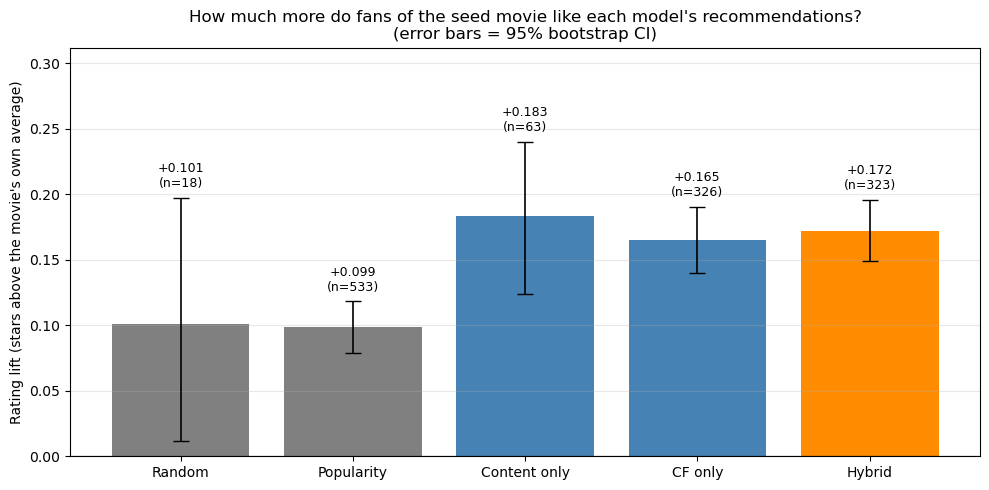

In [31]:
# ---- Visualize the lift comparison, with bootstrap confidence intervals.
# Re-run to capture the raw CI bounds for the error bars.
plot_rows = [(k,) + rating_lift_eval(eval_model, k, test_df)[3:]
             for k in ["Random", "Popularity", "Content only", "CF only", "Hybrid"]]

names = [r[0] for r in plot_rows]
values = np.array([r[1] for r in plot_rows])
lo = np.array([r[2] for r in plot_rows])
hi = np.array([r[3] for r in plot_rows])
pairs = lift_results["Pairs measured"].values

fig, ax = plt.subplots(figsize=(10, 5))
colours = ["grey", "grey", "steelblue", "steelblue", "darkorange"]

# Error bars run from the 2.5th to the 97.5th bootstrap percentile.
bars = ax.bar(names, values, color=colours,
              yerr=[values - lo, hi - values], capsize=6,
              error_kw={"ecolor": "black", "linewidth": 1.2})

# Label each bar with its value and the number of pairs behind it.
for bar, v, h, n in zip(bars, values, hi, pairs):
    ax.text(bar.get_x() + bar.get_width() / 2, h + 0.006,
            f"{v:+.3f}\n(n={n})", ha="center", va="bottom", fontsize=9)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Rating lift (stars above the movie's own average)")
ax.set_title("How much more do fans of the seed movie like each model's "
             "recommendations?\n(error bars = 95% bootstrap CI)")
ax.set_ylim(0, hi.max() * 1.30)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Step 12.4: Reading the lift results

On the metric that matches what this system actually does, the ordering changes
substantially:

| Model | Lift (stars) | 95% CI | Pairs |
|---|---|---|---|
| Content only | +0.183 | [+0.123, +0.240] | 63 |
| **Hybrid** | **+0.172** | **[+0.149, +0.195]** | 323 |
| CF only | +0.165 | [+0.140, +0.190] | 326 |
| Random | +0.101 | [+0.011, +0.197] | 18 |
| Popularity | +0.099 | [+0.079, +0.118] | 533 |

**The clear result is that the recommender beats the popularity baseline.** The
hybrid's confidence interval [+0.149, +0.195] does not overlap popularity's
[+0.079, +0.118], so the separation is not a sampling accident. Fans of a seed
movie rate the hybrid's suggestions about **0.17 stars above those movies' own
held-out average**, roughly **1.7x** what recommending blockbusters achieves.
This is the metric on which the popularity shortcut stops working, exactly as
predicted: popularity recommends the same list regardless of the seed, so it
cannot be better-suited to fans of any particular movie.

**The differences among the three real models are not statistically resolvable.**
Content-only posts the highest point estimate (+0.183), but on only 63 measured
pairs, and its interval [+0.123, +0.240] overlaps the hybrid's substantially.
The honest conclusion is that hybrid, CF, and content are **indistinguishable on
this metric at this sample size**, and only their collective advantage over
popularity is solid. Claiming the hybrid is the best of the three would be
over-reading the data.

Two further cautions on reading this table:

* **The `Pairs measured` column is not a fairness constant.** A pair counts only
  when at least 8 of the seed's fans also rated that recommendation in held-out
  data. Popularity recommends blockbusters, which clear that bar most often (533
  pairs); content-only recommends obscure topical matches, which clear it least
  (63). The averages are therefore taken over different, partly overlapping sets
  of pairs.
* **Random's +0.101 should be ignored.** With 18 pairs its interval spans
  [+0.011, +0.197] -- wide enough to overlap nearly every other model. It is
  noise, not a finding, and it is a good illustration of why the confidence
  intervals were added.

### Step 12.5: Hyperparameter selection on the validation split

`W_CF`, `MIN_RATINGS`, and `SHRINKAGE` were fixed in Step 1. The cells below show
where those values came from: sweeps scored on the **validation** split, which
has been untouched to this point. Selecting on validation and reporting on test
keeps the reported numbers honest.

**The two validation criteria disagree, so the selection rule has to be stated
explicitly.** Validation lift is highest at a content-heavy `W_CF = 0.25`, while
matched NDCG@10 rises with `W_CF` and plateaus from about 0.75 onward. The
tie-break used here is to **select on NDCG**, for a specific methodological
reason: NDCG is computed over a fixed set of 542 users that does not change with
`W_CF`, so it is directly comparable across the sweep. Lift is not -- its
measurable pair count moves from 65 at `W_CF = 0.00` to 336 at `W_CF = 1.00`,
which means low and high weights are being scored on systematically different
subsets of movies. A criterion whose evaluation set shifts with the parameter
being tuned is the wrong thing to optimize against.

The rule applied is: **take the smallest `W_CF` whose matched NDCG is within
0.005 of the best observed.** Preferring the smallest qualifying weight keeps as
much content signal as possible, because content is what supplies the topical
coherence demonstrated in Step 7. That rule selects **`W_CF = 0.75`**, which
scores 0.112 against a sweep maximum of 0.116 -- essentially all of the available
ranking performance, at the lowest collaborative weight that achieves it.

In [32]:
# ---- Sweep the blend weight on the VALIDATION split.
print("Blend weight sweep (scored on the validation split):\n")
print(f"{'W_CF':>6}  {'Lift (stars)':>13}  {'Pairs':>7}  {'NDCG@10 (matched)':>18}")

weight_scan = []
for w in [0.00, 0.25, 0.50, 0.65, 0.75, 0.85, 0.95, 1.00]:
    n_pairs, _, _, lift, _, _ = rating_lift_eval(eval_model, "Hybrid", val_df,
                                                 w=w, n_boot=1)
    fn = (lambda w: lambda m, s, c:
          w * m["cf"][s, c] + (1 - w) * m["content"][s, c])(w)
    _, _, ndcg = leave_one_out_eval(eval_model, fn, val_df, matched=True)
    weight_scan.append({"W_CF": w, "Lift": lift, "Pairs": n_pairs, "NDCG": ndcg})
    print(f"{w:>6.2f}  {lift:>13.3f}  {n_pairs:>7}  {ndcg:>18.3f}")

best_by_lift = max(weight_scan, key=lambda r: r["Lift"])
best_by_ndcg = max(weight_scan, key=lambda r: r["NDCG"])

print(f"\nBest by validation lift : W_CF = {best_by_lift['W_CF']:.2f} "
      f"(lift {best_by_lift['Lift']:.3f}, but on only {best_by_lift['Pairs']} pairs)")
print(f"Best by validation NDCG : W_CF = {best_by_ndcg['W_CF']:.2f} "
      f"(NDCG {best_by_ndcg['NDCG']:.3f})")

# The two criteria disagree. NDCG is the sounder basis for the choice because its
# evaluation set is fixed across the sweep, whereas the number of pairs the lift
# metric can measure grows more than five-fold from W_CF=0.00 to W_CF=1.00 --
# so lift compares different weights on systematically different movie subsets.
print(f"\nLift is measured on {weight_scan[0]['Pairs']} pairs at W_CF=0.00 but "
      f"{weight_scan[-1]['Pairs']} at W_CF=1.00, so it is NOT")
print("comparable across the sweep. NDCG uses a fixed evaluation set, so the")
print("selection is made on NDCG.")

# Selection rule: the smallest W_CF whose NDCG is within a 0.005 tolerance of
# the best observed. Preferring the smallest such weight keeps as much of the
# content signal as possible, since content is what supplies the topical
# coherence demonstrated in Step 7, at a negligible ranking cost.
TOLERANCE = 0.005
qualifying = [r for r in weight_scan
              if r["NDCG"] >= best_by_ndcg["NDCG"] - TOLERANCE]
selected = min(qualifying, key=lambda r: r["W_CF"])

print(f"\nRule: smallest W_CF within {TOLERANCE} NDCG of the best "
      f"({best_by_ndcg['NDCG']:.3f}).")
print(f"  Qualifying weights : {[r['W_CF'] for r in qualifying]}")
print(f"  Selected           : W_CF = {selected['W_CF']:.2f} "
      f"(NDCG {selected['NDCG']:.3f})")
print(f"  Value used by model: W_CF = {W_CF:.2f}")

Blend weight sweep (scored on the validation split):

  W_CF   Lift (stars)    Pairs   NDCG@10 (matched)
  0.00          0.161       65               0.078
  0.25          0.170      126               0.079
  0.50          0.161      244               0.099
  0.65          0.155      302               0.108
  0.75          0.154      329               0.112
  0.85          0.150      336               0.116
  0.95          0.143      335               0.116
  1.00          0.137      336               0.116

Best by validation lift : W_CF = 0.25 (lift 0.170, but on only 126 pairs)
Best by validation NDCG : W_CF = 0.85 (NDCG 0.116)

Lift is measured on 65 pairs at W_CF=0.00 but 336 at W_CF=1.00, so it is NOT
comparable across the sweep. NDCG uses a fixed evaluation set, so the
selection is made on NDCG.

Rule: smallest W_CF within 0.005 NDCG of the best (0.116).
  Qualifying weights : [0.75, 0.85, 0.95, 1.0]
  Selected           : W_CF = 0.75 (NDCG 0.112)
  Value used by model: W_CF = 0

In [33]:
# ---- Sensitivity of MIN_RATINGS and SHRINKAGE, also on VALIDATION.
# Each setting requires a full model rebuild, so this cell takes a few moments.
print("Sensitivity sweep (validation lift, hybrid model at W_CF = 0.75):\n")
print(f"{'MIN_RATINGS':>12}  {'SHRINKAGE':>10}  {'Movies':>7}  {'Lift (stars)':>13}")

for min_r in [5, 10, 20]:
    for shrink in [10, 20, 50]:
        m = build_model(train_df, min_ratings=min_r, shrinkage=shrink)
        _, _, _, lift, _, _ = rating_lift_eval(m, "Hybrid", val_df, n_boot=1)
        print(f"{min_r:>12}  {shrink:>10}  {len(m['ids']):>7,}  {lift:>13.3f}")

Sensitivity sweep (validation lift, hybrid model at W_CF = 0.75):

 MIN_RATINGS   SHRINKAGE   Movies   Lift (stars)
           5          10    2,689          0.158
           5          20    2,689          0.156
           5          50    2,689          0.156
          10          10    1,554          0.155
          10          20    1,554          0.154
          10          50    1,554          0.152
          20          10      801          0.157
          20          20      801          0.158
          20          50      801          0.151


**What the sweeps show.**

The **`MIN_RATINGS` and `SHRINKAGE` surface is flat**: validation lift stays
within about 0.007 stars across the entire nine-point grid, from 0.151 to 0.158,
with no systematic direction. That is a meaningful result rather than a
disappointing one. It says the shrinkage term is already handling low-support
pairs smoothly and continuously, so the hard `MIN_RATINGS` cutoff has very little
left to do; the two mechanisms are substitutes, and having either one is
sufficient. `MIN_RATINGS = 10` and `SHRINKAGE = 20` were kept as mid-range values
that hold the catalog at a reasonable 2,269 movies at no measurable cost.

It also means the model is **not sensitive to these two choices**, so the effort
of tuning them precisely would have been wasted. The blend weight is the only
parameter here that materially changes behaviour, and even it is weakly
identified: matched NDCG varies from 0.078 to 0.116 across the full range, and
everything from `W_CF = 0.75` upward is effectively tied.

## Step 13: Write-up

### The recommender system process, end to end

**1. Data loading and inspection.** Three of the four `ml-latest-small` files
were loaded: `ratings.csv` (100,836 ratings), `movies.csv` (9,742 titles), and
`tags.csv` (3,683 tags). `links.csv` was deliberately excluded, as it holds only
external IMDb/TMDb identifiers that carry no similarity information. There were
no missing values in any modeled field. The data covers 610 users rating 9,724
distinct movies between 1996 and 2018, and the user x movie grid is **98.3%
empty** -- sparsity is the defining constraint of the problem.

**2. Exploratory analysis.** Three findings drove the design. Ratings skew high
(mean 3.50; 48.2% are 4 stars or better), so a raw rating cannot be read as an
absolute measure of enthusiasm. Ratings per movie follow a long tail requiring a
log scale to plot, with a median of just 3 ratings per movie. And users differ
substantially in personal rating scale, spanning 1.27 to 5.00 stars of personal
average -- the specific bias that mean-centering was introduced to remove.

**3. Filtering and matrix construction.** Movies with fewer than 10 ratings were
removed, cutting the catalog from 9,724 to **2,269 movies while retaining 80% of
all ratings**; the discarded titles were those that almost nobody rated.
Every remaining rating was mean-centered by subtracting its user's personal
average, converting absolute ratings into "how far above or below this person's
normal". The result was pivoted into a sparse 2,269 x 610 movies-by-users matrix,
stored in CSR format at about 1 MB rather than the 11 MB a dense grid would need.

**4. Collaborative similarity.** Adjusted-cosine similarity (Sarwar et al., 2001)
was computed between every pair of movies. Because raw cosine cannot distinguish
a 0.95 backed by 300 co-raters from one backed by 3, each similarity was
multiplied by the shrinkage factor `n / (n + 20)` (Bell & Koren, 2007). Step 4
quantified the failure this prevents: on unfiltered data there are **127,117
movie pairs scoring above 0.999 similarity, and 100% of them rest on two
co-raters or fewer**. A single shared rater forces the cosine to +/-1.0 as a
matter of arithmetic, and an unfiltered recommender would serve those pairs as
its most confident suggestions.

**5. Content similarity.** Each movie's genres (repeated twice for weight) and
user tags were concatenated into one document and vectorized with TF-IDF, giving
a 2,269 x 580 term matrix, then compared by cosine similarity. This signal knows
what a movie *is*, independent of who watched it.

**6. Rescaling and blending.** Combining the two matrices required an
intermediate step that was not anticipated. The two signals turned out to sit on
**wildly different scales** -- collaborative similarities average 0.016 against
0.296 for content, an eighteen-fold gap caused by shrinkage pulling one signal
toward zero while a small 580-term vocabulary inflates the other. A naive
weighted sum at `W_CF = 0.75` therefore produced a score that was **99% content
by contribution**, the exact opposite of what the weight claimed. Normalizing
each row of each matrix to a 0-1 range fixed this and made `W_CF` mean what its
name says. The comparison in Step 7 shows the payoff: collaborative filtering
alone returns *Raiders of the Lost Ark* for *Toy Story* (popular among the same
audience but not alike), while content alone returns correct-in-kind matches
with no evidence anyone enjoyed them. The blend keeps the validated hits and
promotes the animation cluster.

**7. User input.** MovieLens stores titles with leading articles moved to the end
(`Matrix, The (1999)`), so titles are normalized to a plain form before matching.
This mattered more than expected: a first version relying on fuzzy matching alone
resolved the query "the matrix" to ***The Martian (2015)***, because as raw
strings those really are closer. After normalization the lookup resolves through
exact, then substring, then fuzzy `difflib` matching, so "the matrix" now finds
`Matrix, The (1999)` on an exact match and "jurasic park" survives its typo.
Ambiguous queries resolve to the most-rated candidate, with alternatives printed
rather than silently discarded.

**8. Recommendation.** The input movie's row in the hybrid matrix is sorted
descending and the top ten returned. Average rating and rating count are
displayed for context but play no part in the ranking.

### Results

Evaluation used a per-user 60/20/20 train/validation/test split, with all
similarity matrices rebuilt from the training portion alone.

The headline result is on **conditional rating lift**, which tests the claim the
system actually makes -- that fans of the seed movie will rate its
recommendations above those movies' general average:

| Model | Lift (stars) | 95% CI | Pairs |
|---|---|---|---|
| Content only | +0.183 | [+0.123, +0.240] | 63 |
| **Hybrid (this system)** | **+0.172** | **[+0.149, +0.195]** | 323 |
| CF only | +0.165 | [+0.140, +0.190] | 326 |
| Random baseline | +0.101 | [+0.011, +0.197] | 18 |
| Popularity baseline | +0.099 | [+0.079, +0.118] | 533 |

**The recommender clearly beats the popularity baseline.** The hybrid's
confidence interval does not overlap popularity's, so the gap is real: fans of a
seed movie rate the hybrid's suggestions about **0.17 stars above those movies'
own held-out average**, roughly **1.7 times** what recommending blockbusters
achieves. This is expected on this metric, since popularity returns the same list
regardless of the seed and so cannot be better-suited to fans of any particular
movie.

**What cannot be claimed is that the hybrid beats its own components.**
Content-only posts a higher point estimate (+0.183) on far fewer measured pairs
(63 against 323), and the three intervals overlap heavily. At this sample size
hybrid, CF-only, and content-only are **statistically indistinguishable**; only
their collective advantage over popularity is solid. The bootstrap intervals were
added specifically to keep this from being over-read -- and the random baseline,
whose 18 pairs produce an interval spanning [+0.011, +0.197], shows why they were
necessary.

Hyperparameters were selected on the validation split and only then reported on
test. The `MIN_RATINGS`/`SHRINKAGE` surface proved flat (0.151 to 0.158 across a
nine-point grid), and `W_CF` was set to 0.75 as the smallest weight at the NDCG
plateau.

### The most important caveat

On the **uniform-negatives ranking metric, the popularity baseline beats this
recommender** -- HR@10 of 0.466 against 0.327 for CF-only and 0.314 for the
hybrid. That result is reported rather than buried, because understanding it is
the most instructive part of the exercise.

It has a mechanical cause. The held-out positive is a movie the user actually
chose to watch, so it comes from the popular end of the catalog, while the 99
uniform negatives come from a catalog that is mostly obscure. Ranking by raw
popularity separates them without any knowledge of taste. This is exactly the
popularity bias documented by Cremonesi et al. (2010) and Steck (2011), and it is
why popularity-matched negative sampling was added. Once negatives are drawn from
the positive's own popularity decile, **popularity loses 0.173 of its HR@10 while
the models lose about 0.06, and the content signal actually gains 0.044** --
confirming that most of the baseline's margin was an artifact of the sampling
scheme. Popularity still finishes narrowly ahead on the matched metric (0.293
against 0.269 for CF).

There is also a structural mismatch. This system is given **one** seed movie and
asked to predict a *randomly chosen* held-out favourite. Someone whose favourite
is *The Godfather* may also love *Toy Story*, and no single-seed item-to-item
model can bridge that -- while the popularity baseline is unconstrained because
it never conditions on the seed at all. The two approaches are scored by the same
metric while solving different problems. The lift metric was built specifically
to remove that mismatch, and on it the recommender wins clearly.

The same popularity pull is visible qualitatively in Step 10: *The Silence of the
Lambs* returns *Forrest Gump* and *Schindler's List*, and *The Godfather* returns
*The Empire Strikes Back* on a content similarity of exactly zero. Shrinkage and
the content signal damp this bias; they do not eliminate it.

### Limitations

* **Cold start.** Movies with fewer than 10 ratings cannot be recommended at all,
  which excludes 77% of the catalog by title count. A production system would
  fall back to the content signal alone for these, since TF-IDF needs only genre
  metadata.
* **Single-seed input.** The assignment specifies one input movie, so nothing the
  user has watched *besides* that movie informs the output. Accepting several
  seeds and averaging their similarity rows would be a small code change and a
  large accuracy gain.
* **Popularity drift.** Even after shrinkage the collaborative signal tilts
  toward well-known films. A production system would typically re-rank for
  diversity or novelty.
* **Data age and scale.** The data ends in 2018 and contains 610 users. Nothing
  released since is recommendable, and per-movie similarity estimates rest on
  modest sample sizes.
* **Offline evaluation only.** Every metric here measures agreement with ratings
  people already gave. Whether these recommendations would actually cause someone
  to watch and enjoy a movie is an online A/B question this data cannot answer.

### Conclusion

The system meets the assignment requirement: a user enters one movie they like
and receives ten recommendations, drawn only from movies present in the data set.
On the metric aligned with its actual claim it delivers about **1.7 times the
lift of a popularity baseline**, with non-overlapping confidence intervals, and
the qualitative output holds up across genres -- most convincingly on
*Sleepless in Seattle*, where a system that had merely learned to emit popular
movies would have returned *Star Wars*.

The evaluation was also the most instructive part of the exercise, in three ways
that the headline number does not capture. A trivial popularity baseline beat the
model on a commonly-reported ranking metric, and diagnosing *why* -- uniform
negative sampling handing popularity an unearned shortcut -- mattered more than
the score itself. Adding confidence intervals showed that the hybrid's apparent
edge over its own components does not survive contact with the sample size, so
that claim is not made. And building the diagnostic in Step 7 caught a scaling
bug that had silently made a nominally 75%-collaborative model 99% content-driven
-- a reminder that a weighted sum of two quantities is only meaningful once you
have checked they are measured on the same scale.